<a href="https://colab.research.google.com/github/Nabilsultan222/Diabetes-Risk-Prediction-using-Machine-Learning-and-Neural-Networks/blob/main/Diabetes_Risk_Prediction_using_Machine_Learning_and_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve
from google.colab import drive

Load the dataset (inser)
dataset = pd.read_csv()

Mounted at /content/drive


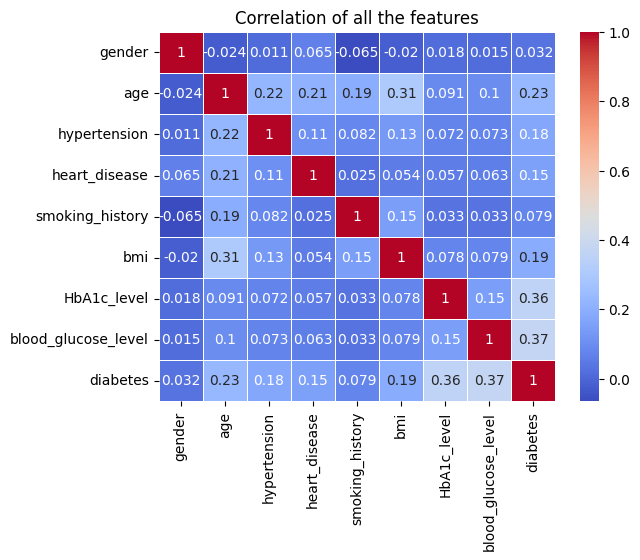

In [ ]:
continuous_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
binary_features = ['hypertension', 'heart_disease', 'diabetes']
categorical_features = ['gender', 'smoking_history']

# Imputing features
imputer_median = SimpleImputer(strategy = 'median')
imputer_mode = SimpleImputer(strategy = 'most_frequent')

dataset[continuous_features] = imputer_median.fit_transform(dataset[continuous_features])
dataset[binary_features] = imputer_mode.fit_transform(dataset[binary_features])
dataset[categorical_features] = imputer_mode.fit_transform(dataset[categorical_features])

# Label encoding
dataset['gender'] = LabelEncoder().fit_transform(dataset['gender'])
dataset['smoking_history'] = LabelEncoder().fit_transform(dataset['smoking_history'])

# Feature scaling
dataset[continuous_features] = StandardScaler().fit_transform(dataset[continuous_features])

# Correlation matrix for heatmap
features = ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']
correlation = dataset[features].corr(method = 'pearson')

# Heatmap plotting
plt.figure()
sns.heatmap(correlation, annot = True, cmap = 'coolwarm', linewidths = 0.5)
plt.title('Correlation of all the features')
plt.show()

   diabetes  count  percentage
0         0  92366      92.366
1         1   7634       7.634



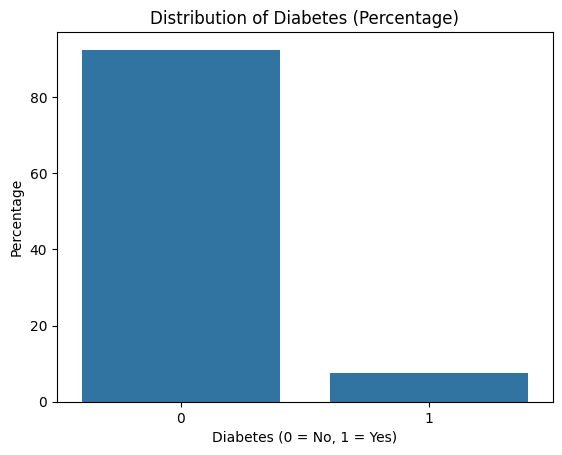


Difference in percentage: 84.732%
The classes do not have equal instances (imbalanced dataset)


In [ ]:
class_counts = dataset.groupby("diabetes").size()

columns = ['diabetes', 'count', 'percentage']
diabetes_classes = [0, 1]
count = []
percentage = []

total_instances = len(dataset)
for i in diabetes_classes:
    count.append(class_counts[i])
    percent = (class_counts[i] / total_instances) * 100
    percentage.append(percent)

imbalanced = pd.DataFrame(list(zip(diabetes_classes, count, percentage)), columns = columns)
print(imbalanced)
print()

sns.barplot(data = imbalanced, x = 'diabetes', y = 'percentage')
plt.title('Distribution of Diabetes (Percentage)')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Percentage')
plt.show()
print()

class_difference = abs(percentage[0] - percentage[1])
print(f"Difference in percentage: {class_difference}%")
if class_difference < 5:
    print("The classes have approximately equal instances (balanced dataset)")
else:
    print("The classes do not have equal instances (imbalanced dataset)")

Shape of the dataset: (100000, 9)
Number of rows: 100000
Number of columns: 9

First 10 rows of the dataset:
   gender       age  hypertension  heart_disease  smoking_history       bmi  \
0       0  1.779245           0.0            1.0                4 -0.337160   
1       0  0.045902           0.0            0.0                0  0.001174   
2       1 -0.656805           0.0            0.0                4  0.001174   
3       0 -0.282028           0.0            0.0                0 -0.613545   
4       1  1.591856           1.0            1.0                1 -1.139312   
5       0 -1.031581           0.0            0.0                4  0.001174   
6       0  0.092749           0.0            0.0                4 -1.271151   
7       0  1.732397           0.0            0.0                0 -0.548419   
8       1 -0.000945           0.0            0.0                4  1.005056   
9       0 -0.469416           0.0            0.0                4  0.001174   

   HbA1c_level  blood

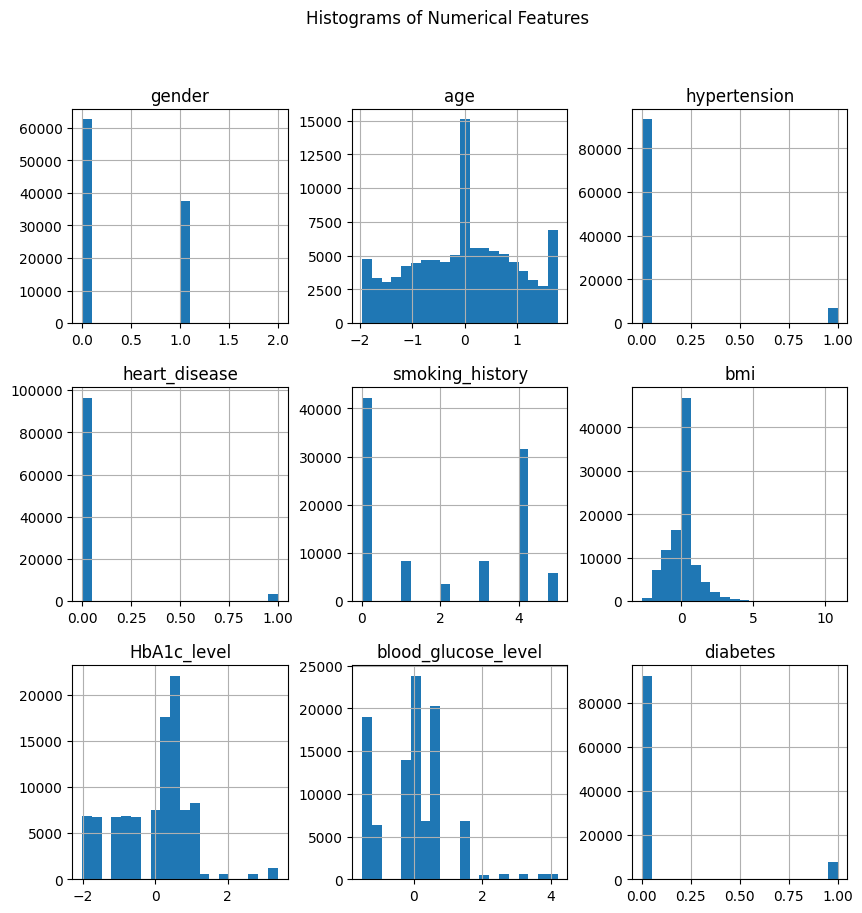

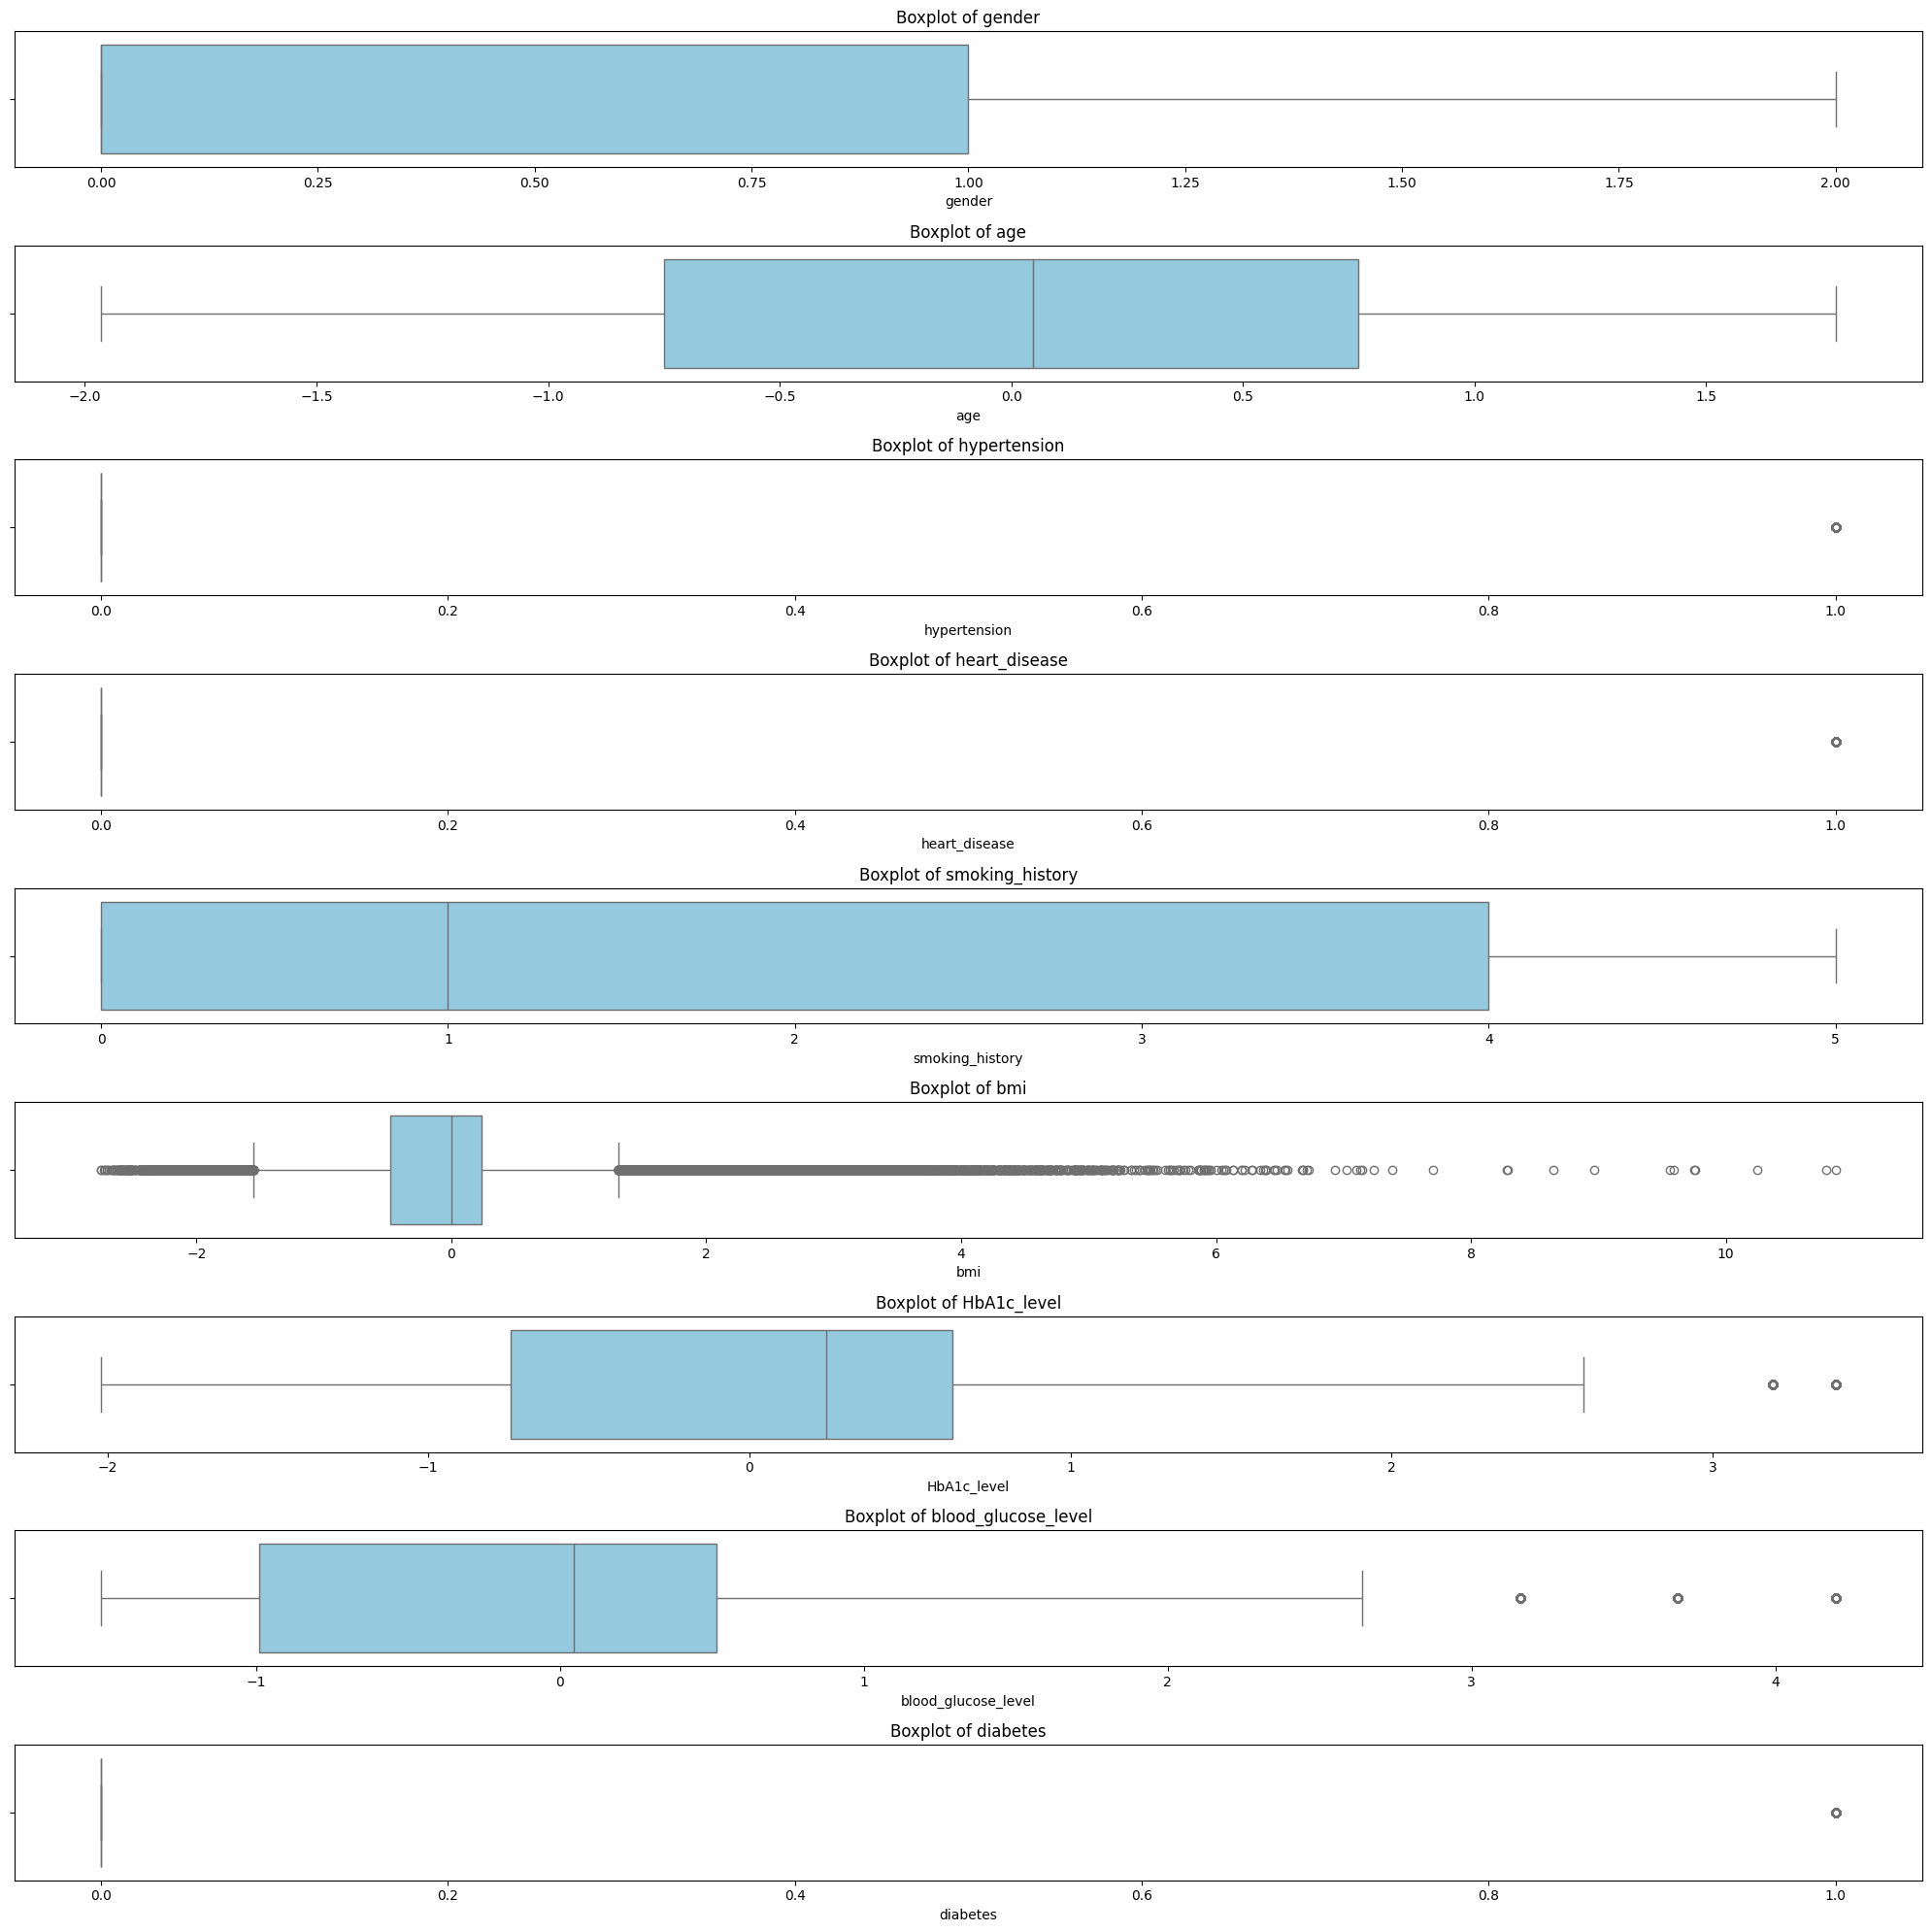

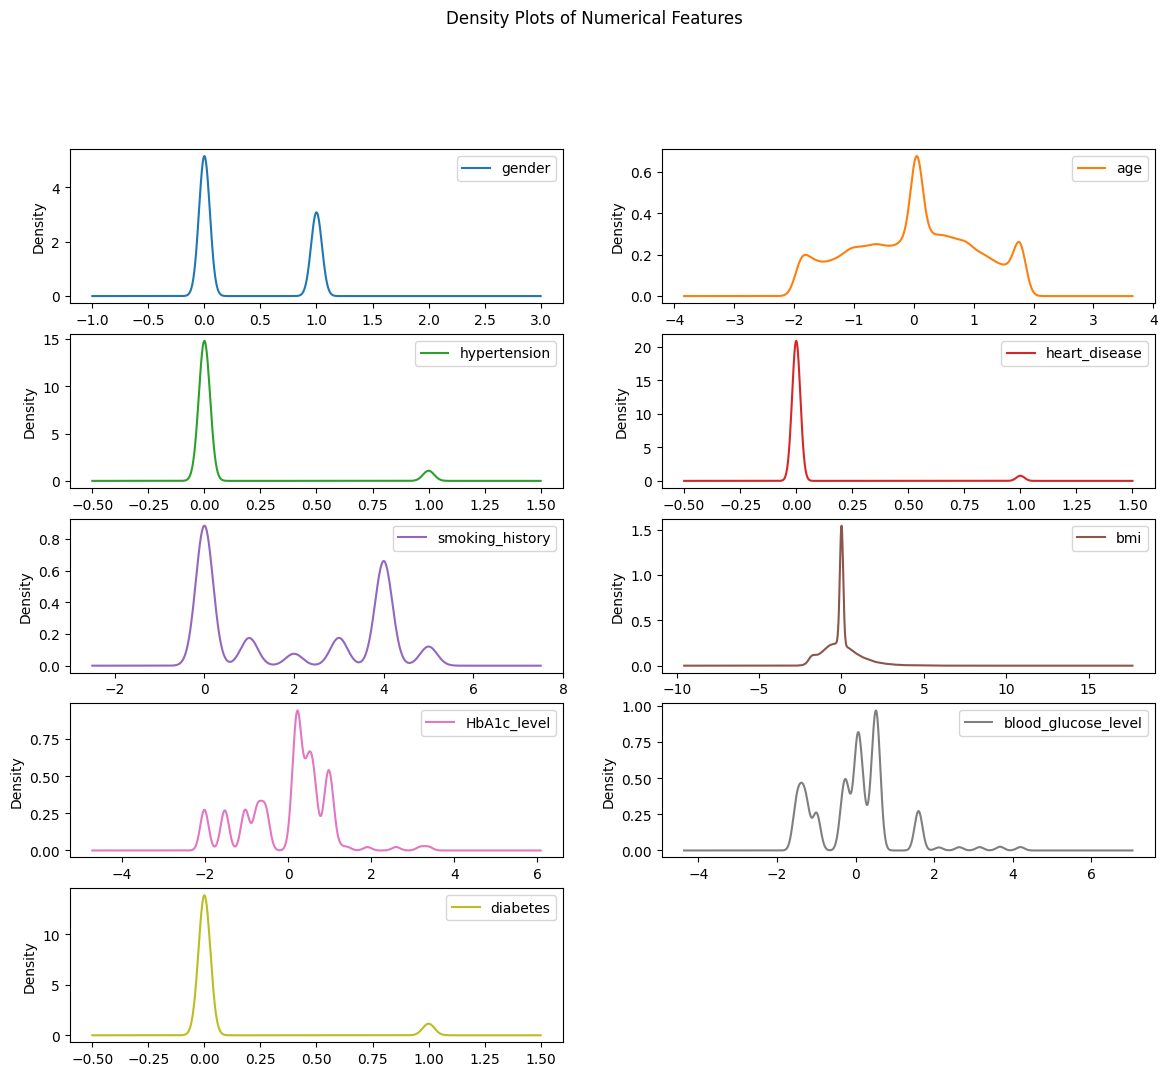

In [ ]:
print("Shape of the dataset:", dataset.shape)
print("Number of rows:", dataset.shape[0])
print("Number of columns:", dataset.shape[1])
print("\nFirst 10 rows of the dataset:")
print(dataset.head(10))

print("\nFeature names and datatypes:")
print(dataset.info())

numerical_data = dataset.select_dtypes(include = 'number')
numerical_features = numerical_data.columns.tolist()
print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

print("\nSummary statistics of numerical features:")
print(numerical_data.describe().T)

print("\nVariance of numerical features:")
print(numerical_data.var())

print("\nSkewness of numerical features:")
print(numerical_data.skew())

numerical_data.hist(figsize = (10, 10), bins = 20)
plt.suptitle('Histograms of Numerical Features')
plt.show()

plt.figure(figsize = (20, 20))
numeric_cols = dataset.select_dtypes(include = ['int64', 'float64']).columns
for i, col in enumerate(numeric_cols, 1):
  plt.subplot(len(numeric_cols), 1, i)
  sns.boxplot(x = dataset[col], color = 'skyblue')
  plt.title(f'Boxplot of {col}')
  plt.tight_layout()
plt.show()

numerical_data.plot(kind = 'density', figsize = (14, 14), subplots = True, layout = (6, 2), title = "Density Plots of Numerical Features", sharex = False)
plt.show()

Shape of X_train: (70000, 8)
Shape of X_test: (30000, 8)
Shape of y_train: (70000,)
Shape of y_test: (30000,)

Original class distribution (%):
diabetes
0.0    92.366
1.0     7.634
Name: count, dtype: float64

Train set class distribution (%):
diabetes
0.0    92.365714
1.0     7.634286
Name: count, dtype: float64

Test set class distribution (%):
diabetes
0.0    92.366667
1.0     7.633333
Name: count, dtype: float64


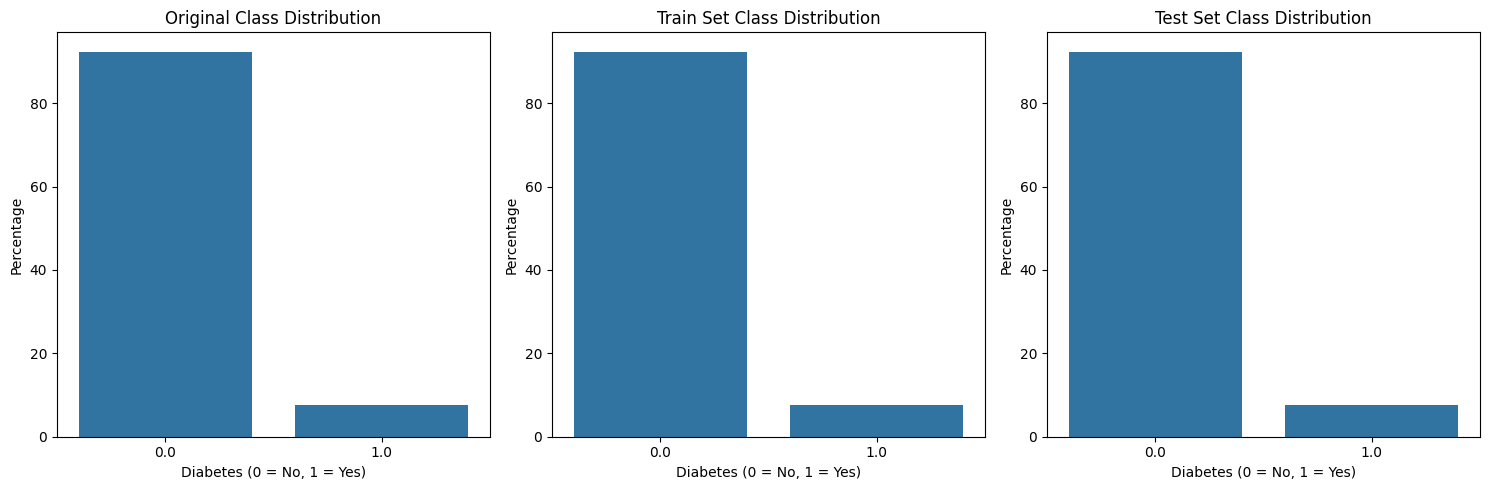

In [ ]:
X = dataset.drop(columns = ['diabetes'])
y = dataset['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, stratify = y, random_state = 42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

original_distribution = y.value_counts() / len(y) * 100
train_distribution = y_train.value_counts() / len(y_train) * 100
test_distribution = y_test.value_counts() / len(y_test) * 100

print("\nOriginal class distribution (%):")
print(original_distribution)
print("\nTrain set class distribution (%):")
print(train_distribution)
print("\nTest set class distribution (%):")
print(test_distribution)

# Visualize class distribution
original_df = pd.DataFrame({'diabetes': original_distribution.index, 'percentage': original_distribution.values})
train_df = pd.DataFrame({'diabetes': train_distribution.index, 'percentage': train_distribution.values})
test_df = pd.DataFrame({'diabetes': test_distribution.index, 'percentage': test_distribution.values})

plt.figure(figsize = (15, 5))

plt.subplot(1, 3, 1)
sns.barplot(data = original_df, x = 'diabetes', y = 'percentage')
plt.title('Original Class Distribution')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Percentage')

plt.subplot(1, 3, 2)
sns.barplot(data = train_df, x = 'diabetes', y = 'percentage')
plt.title('Train Set Class Distribution')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Percentage')

plt.subplot(1, 3, 3)
sns.barplot(data = test_df, x = 'diabetes', y = 'percentage')
plt.title('Test Set Class Distribution')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Percentage')

plt.tight_layout()
plt.show()

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9325 - loss: 0.2400 - val_accuracy: 0.9516 - val_loss: 0.1416
Epoch 2/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9553 - loss: 0.1320 - val_accuracy: 0.9530 - val_loss: 0.1379
Epoch 3/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9579 - loss: 0.1264 - val_accuracy: 0.9536 - val_loss: 0.1340
Epoch 4/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9583 - loss: 0.1245 - val_accuracy: 0.9547 - val_loss: 0.1315
Epoch 5/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9591 - loss: 0.1220 - val_accuracy: 0.9557 - val_loss: 0.1297
Epoch 6/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9589 - loss: 0.1220 - val_accuracy: 0.9558 - val_loss: 0.1284
Epoch 7/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9595 - loss: 0.1194 - val_accuracy: 0.9571 - val_loss: 0.1282
Epoch 8/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9593 - loss: 0.1185 - val_accuracy: 0.9561

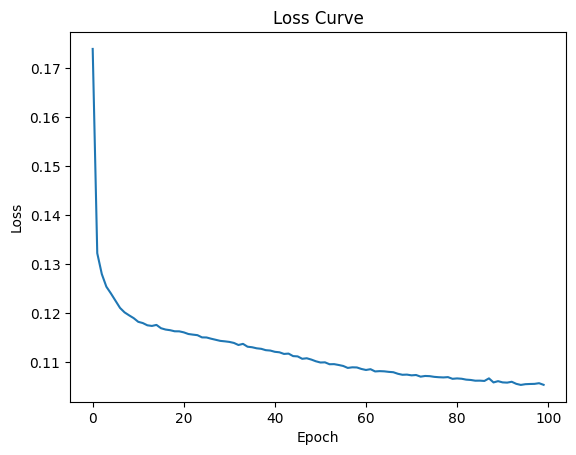

938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9640 - loss: 0.1138
Testing Accuracy: 96.27%


In [ ]:
# Neural Network
model_NN = Sequential([Dense(128, activation = 'relu', input_shape = (X_train.shape[1],)), Dense(2, activation = 'softmax')])

model_NN.compile(optimizer = Adam(0.001), loss = SparseCategoricalCrossentropy(from_logits = False), metrics = ['accuracy'])

history = model_NN.fit(X_train, y_train, epochs = 100, batch_size = 128, validation_split = 0.2)

plt.plot(history.history['loss'])
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

test_loss, test_accuracy = model_NN.evaluate(X_test, y_test)
print(f"Testing Accuracy: {round(test_accuracy * 100, 2)}%")

In [ ]:
# Logistic Regression
model_Log = LogisticRegression(max_iter = 1000)
model_Log.fit(X_train, y_train)

y_pred = model_Log.predict(X_test)

accuracy = model_Log.score(X_test, y_test)
print(f"Test Accuracy: {round(accuracy * 100, 2)}%\n")

Test Accuracy: 95.35%



In [ ]:
# KNN Classifier
model_KNN = KNeighborsClassifier(n_neighbors = 5, weights = 'distance')
model_KNN.fit(X_train, y_train)

y_pred = model_KNN.predict(X_test)

accuracy = model_KNN.score(X_test, y_test)
print(f"Test Accuracy: {round(accuracy * 100, 2)}%\n")

Test Accuracy: 95.27%



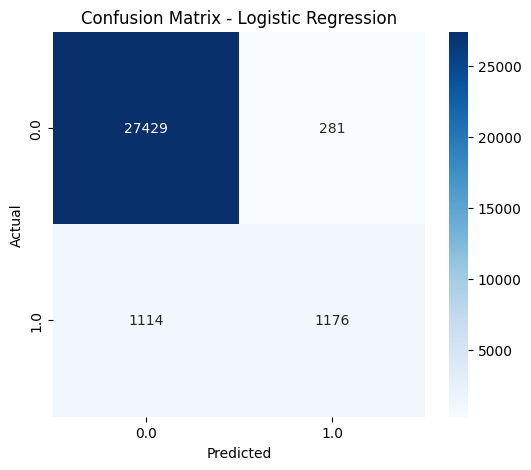

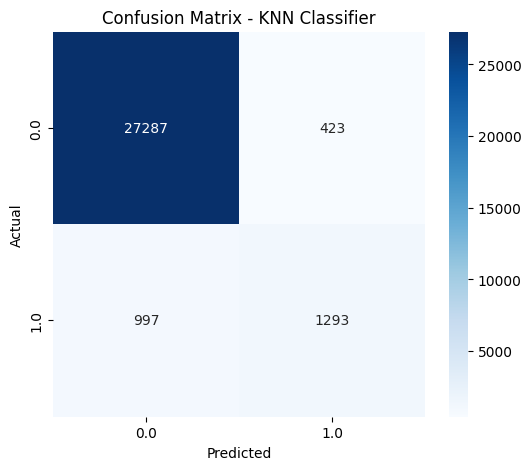

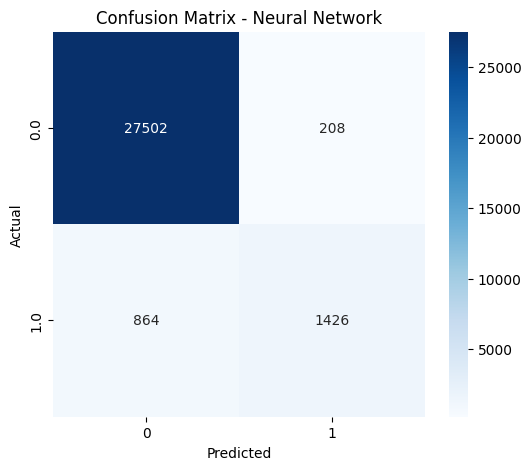

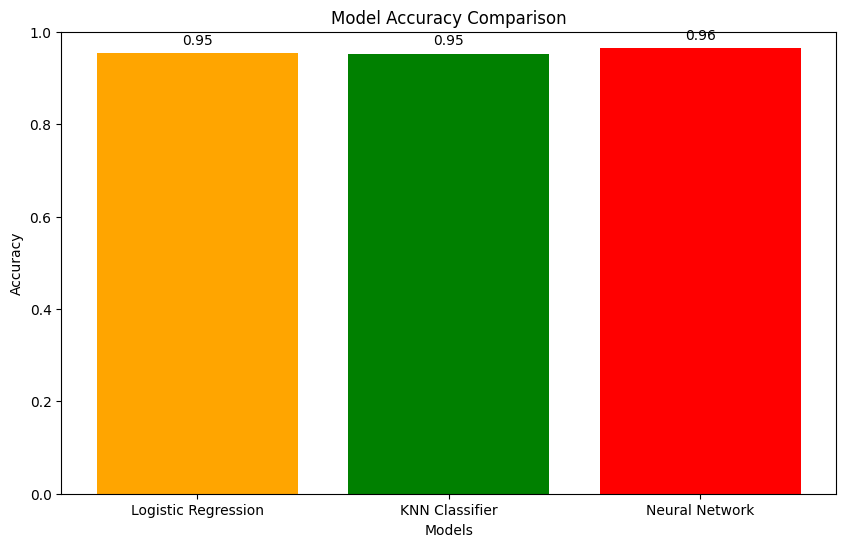

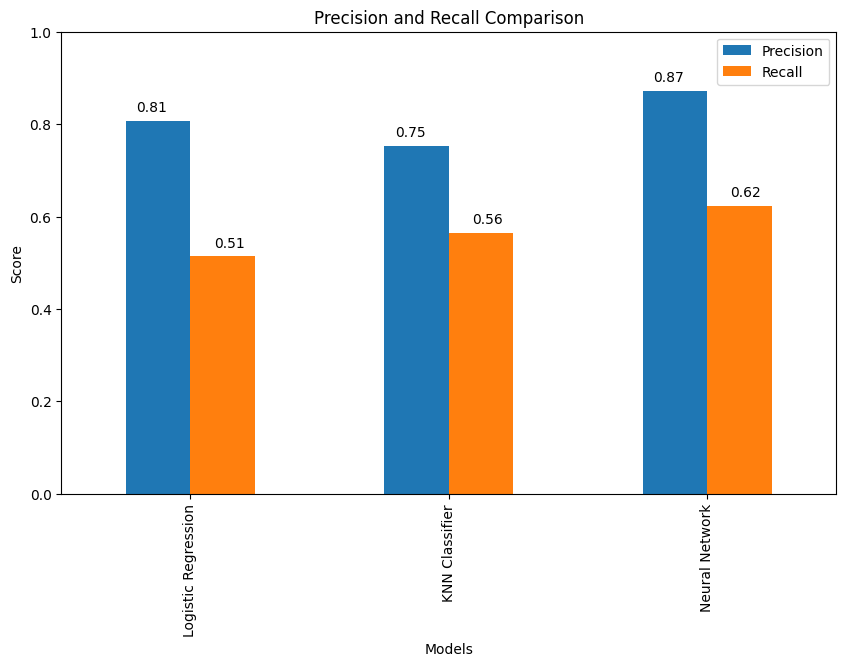

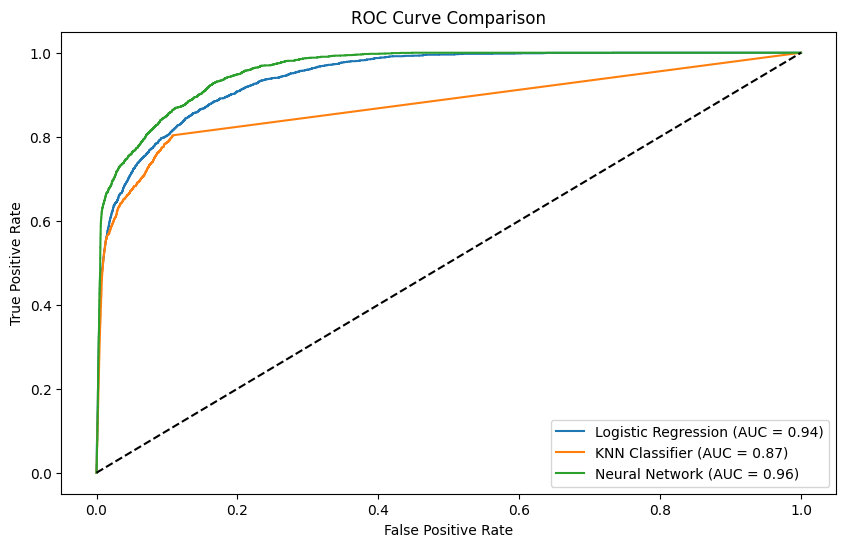

Logistic Regression: Accuracy = 0.95, Precision = 0.81, Recall = 0.51, AUC = 0.94
KNN Classifier: Accuracy = 0.95, Precision = 0.75, Recall = 0.56, AUC = 0.87
Neural Network: Accuracy = 0.96, Precision = 0.87, Recall = 0.62, AUC = 0.96


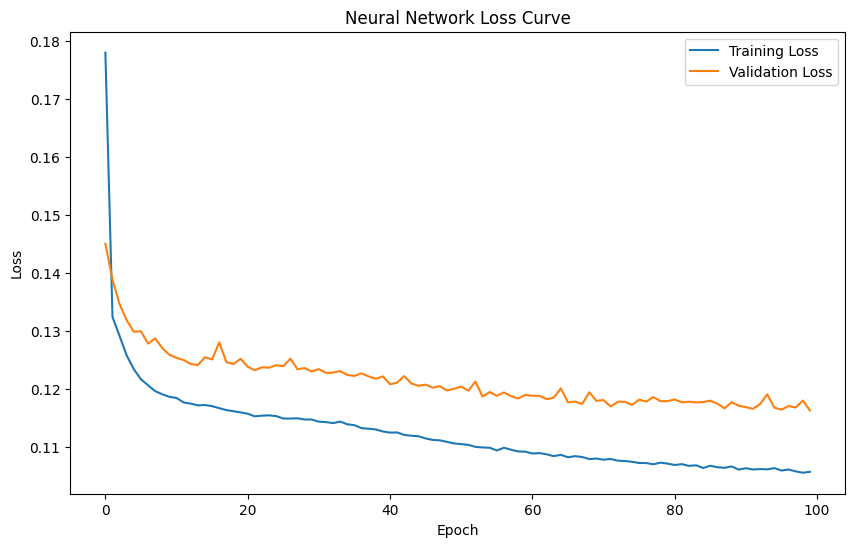

In [ ]:
# Model Evaluation
models = {'Logistic Regression': model_Log, 'KNN Classifier': model_KNN, 'Neural Network': model_NN}

accuracies = {}
precisions = {}
recalls = {}
auc_scores = {}

for name, model in models.items():
    if name == 'Neural Network':
        _, accuracy = model.evaluate(X_test, y_test, verbose=0)
        y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
        y_proba = model.predict(X_test, verbose=0)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    accuracies[name] = accuracy if name == 'Neural Network' else model.score(X_test, y_test)
    precisions[name] = precision_score(y_test, y_pred)
    recalls[name] = recall_score(y_test, y_pred)
    auc_scores[name] = roc_auc_score(y_test, y_proba)

    conf_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
    plt.figure(figsize=(6, 5))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

# Bar Chart for Accuracy
plt.figure(figsize=(10, 6))
plt.bar(accuracies.keys(), accuracies.values(), color=['orange', 'green', 'red'])
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
for i, v in enumerate(accuracies.values()):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
plt.show()

# Precision and Recall Comparison
metrics = pd.DataFrame({'Precision': precisions, 'Recall': recalls})
metrics.plot(kind='bar', figsize=(10, 6))
plt.xlabel('Models')
plt.ylabel('Score')
plt.title('Precision and Recall Comparison')
plt.ylim(0, 1)
for i, (p, r) in enumerate(zip(precisions.values(), recalls.values())):
    plt.text(i - 0.15, p + 0.02, f'{p:.2f}', ha='center')
    plt.text(i + 0.15, r + 0.02, f'{r:.2f}', ha='center')
plt.legend(['Precision', 'Recall'])
plt.show()

# ROC Curve
plt.figure(figsize=(10, 6))
for name, model in models.items():
    if name == 'Neural Network':
        y_proba = model.predict(X_test, verbose=0)[:, 1]
    else:
        y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_scores[name]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

# Print Metrics
for name in models.keys():
    print(f"{name}: Accuracy = {accuracies[name]:.2f}, Precision = {precisions[name]:.2f}, "
          f"Recall = {recalls[name]:.2f}, AUC = {auc_scores[name]:.2f}")

# Loss Curve for Neural Network
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Neural Network Loss Curve')
plt.legend()
plt.show()

In [ ]:
a=24241219%20
print(a+1)